# Лабораторная работа 2. Классификация. Нейронные сети

Цель — изучить пять семейств классификаторов Scikit-Learn и нейронную сеть TensorFlow, сравнить качество и исследовать влияние гиперпараметров. Настройки выбираются на обучающих данных; итоговые модели оцениваются на общей тестовой выборке.

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Поддерживаем исходное имя и имя с суффиксом после скачивания
csv_files = sorted(Path('.').glob('tic_tac_toe_958*.csv'))
if not csv_files:
    from google.colab import files
    files.upload()
    csv_files = sorted(Path('.').glob('tic_tac_toe_958*.csv'))

data = pd.read_csv(csv_files[0])
print(data.head())

  TL TM TR ML MM MR BL BM BR  class
0  x  x  x  x  o  o  x  o  o   True
1  x  x  x  x  o  o  o  x  o   True
2  x  x  x  x  o  o  o  o  x   True
3  x  x  x  x  o  o  o  b  b   True
4  x  x  x  x  o  o  b  o  b   True


Первые строки показывают категориальные состояния клеток и логическую метку исхода. Во всех пяти показанных позициях победили крестики, но по такому фрагменту нельзя судить о балансе классов всего набора — он проверяется ниже.

In [2]:
print("Размер датасета:", data.shape)

Размер датасета: (958, 10)


В данных 958 объектов и 10 столбцов: девять входных признаков и одна целевая метка. Это небольшой набор; после выделения теста обучение будет выполняться на нескольких сотнях позиций, поэтому отдельные тестовые ошибки заметно влияют на проценты качества.

In [3]:
print(f"Пропуски: {data.isnull().sum()}")
print("Дубликаты:", data.duplicated().sum())
print("Распределение классов:")
print(data["class"].value_counts())

Пропуски: TL       0
TM       0
TR       0
ML       0
MM       0
MR       0
BL       0
BM       0
BR       0
class    0
dtype: int64
Дубликаты: 0
Распределение классов:
class
True     626
False    332
Name: count, dtype: int64


### Описание данных и результат проверки

В наборе 958 конечных позиций игры в крестики-нолики: девять столбцов описывают клетки доски, `class` — наличие победы крестиков. `x` и `o` обозначают занятые клетки, `b` — пустую; `True` означает победу `x`, `False` — её отсутствие, включая ничью. Одна строка описывает позицию, а не последовательность ходов партии.

Пропусков и повторяющихся строк нет, поэтому заполнять значения или удалять дубликаты не требуется. Победы `x` составляют 65,3% данных (626 позиций), остальные исходы — 34,7% (332). Из-за такого соотношения одна Accuracy может скрывать ошибки на меньшем классе, поэтому далее также рассматриваются Precision, Recall, F1 и ROC-AUC.

In [4]:
X = data.drop(columns = "class")
X = pd.get_dummies(X, dtype = int)
y = data["class"].astype(int)

### Подготовка данных

Девять категориальных признаков заменены 27 индикаторами: например, `MM_o=1` означает нолик в центре, а `MM_o=0` — его отсутствие. Кодирование не задаёт искусственный порядок между `x`, `o` и `b`. Для каждой клетки ровно один из трёх индикаторов равен 1; признаки внутри такой тройки зависимы. Все признаки имеют диапазон 0–1, поэтому дополнительное масштабирование здесь не применяется. Цель 1 соответствует победе `x`, цель 0 — её отсутствию.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

### Разбиение

Модели обучаются на 766 позициях и проверяются на других 192. Стратификация сохранила соотношение классов: в тесте 125 побед `x` и 67 остальных исходов. Поэтому различия результатов моделей не связаны с разными тестовыми объектами. Одна ошибка меняет тестовую Accuracy примерно на 0,52 процентного пункта; небольшие разрывы следует оценивать с учётом размера теста.

### Метрики качества

Положительный класс — победа `x`. Precision, Recall и F1 рассчитываются для этого класса.

| Метрика | Фактический смысл |
| --- | --- |
| Accuracy | Доля правильно распознанных позиций среди всех объектов. |
| Precision | Доля настоящих побед среди позиций, которые модель назвала победами. |
| Recall | Доля найденных побед среди всех настоящих побед. |
| F1-score | Гармоническое среднее Precision и Recall; оценивает их совместный уровень, а не долю верных ответов. |
| ROC-AUC | Доля пар «победа — непобеда», упорядоченных по оценке модели верно; равные оценки учитываются наполовину. 1 означает полное правильное ранжирование. |

Ложноположительный ответ — непобедная позиция названа победой; ложноотрицательный — настоящая победа пропущена.

In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

model = GaussianNB()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Получаем вероятности положительного класса
y_prob = model.predict_proba(X_test)[:, 1]

print("Метрики качества GaussianNB")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))

Метрики качества GaussianNB
Accuracy:  0.6875
Precision: 0.7443609022556391
Recall: 0.792
F1-score: 0.7674418604651163
ROC-AUC: 0.7835223880597015


### Интерпретация GaussianNB

Верно распознаны 132 из 192 позиций, допущено 60 ошибок: 26 настоящих побед пропущены, 34 непобедные позиции названы победами. Precision = 74,4% означает, что примерно четверть ответов «победа» ошибочна; Recall = 79,2% — что пропущена примерно пятая часть побед. F1 = 0,767 показывает, что сочетание точности и полноты остаётся слабым.

ROC-AUC = 0,784 выше случайного ориентира 0,5: модель различает классы по своим оценкам, но разделение неполное. Accuracy = 68,8% лишь немного выше постоянного предсказания более частого класса (65,1% на тесте).

In [7]:
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB()
mnb.fit(X_train, y_train)
mnb_pred = mnb.predict(X_test)
mnb_prob = mnb.predict_proba(X_test)[:, 1]

print("Метрики качества MultinomialNB:")
print("Accuracy", accuracy_score(y_test, mnb_pred))
print("Precision", precision_score(y_test, mnb_pred))
print("Recall", recall_score(y_test, mnb_pred))
print("F1-score", f1_score(y_test, mnb_pred))
print("ROC-AUC", roc_auc_score(y_test, mnb_prob))

Метрики качества MultinomialNB:
Accuracy 0.7239583333333334
Precision 0.74
Recall 0.888
F1-score 0.8072727272727273
ROC-AUC 0.7888955223880598


### Интерпретация MultinomialNB

Модель правильно распознала 139 из 192 позиций: пропустила 14 побед и выдала 39 ложных побед. По сравнению с GaussianNB найдено на 12 побед больше, но добавилось пять ложных положительных ответов. Рост Recall до 88,8% поэтому сопровождается Precision около прежнего уровня — 74,0%.

F1 вырос до 0,807: увеличение полноты перевесило небольшое снижение точности положительных ответов. ROC-AUC изменился слабо, до 0,789, поэтому улучшение решений классов не сопровождается столь же заметным улучшением ранжирования.

In [8]:
from sklearn.naive_bayes import ComplementNB

cnb = ComplementNB()
cnb.fit(X_train, y_train)
cnb_pred = cnb.predict(X_test)
cnb_prob = cnb.predict_proba(X_test)[:, 1]

print("Метрики качества ComplementNB:")
print("Accuracy:", accuracy_score(y_test, cnb_pred))
print("Precision:", precision_score(y_test, cnb_pred))
print("Recall:", recall_score(y_test, cnb_pred))
print("F1-score:", f1_score(y_test, cnb_pred))
print("ROC-AUC:", roc_auc_score(y_test, cnb_prob))

Метрики качества ComplementNB:
Accuracy: 0.6770833333333334
Precision: 0.7889908256880734
Recall: 0.688
F1-score: 0.7350427350427351
ROC-AUC: 0.7888955223880598


### Интерпретация ComplementNB

Выдано 23 ложных победы — на 16 меньше, чем у MultinomialNB, но пропущено 39 настоящих побед — на 25 больше. Precision = 78,9% показывает более надёжные положительные ответы, а Recall = 68,8% — потерю почти трети побед. В сумме ошибок стало больше: 62 вместо 53, а F1 снизился до 0,735.

ROC-AUC совпал с MultinomialNB (0,789), несмотря на разные количества ошибок. Следовательно, одинаковое качество ранжирования не означает одинаковый баланс Precision и Recall при решении о классе.

In [9]:
from sklearn.naive_bayes import BernoulliNB

bnb = BernoulliNB()
bnb.fit(X_train, y_train)
bnb_pred = bnb.predict(X_test)
bnb_prob = bnb.predict_proba(X_test)[:, 1]

print("Метрики качества BernoulliNB:")
print("Accuracy:", accuracy_score(y_test, bnb_pred))
print("Precision:", precision_score(y_test, bnb_pred))
print("Recall:", recall_score(y_test, bnb_pred))
print("F1-score:", f1_score(y_test, bnb_pred))
print("ROC-AUC:", roc_auc_score(y_test, bnb_prob))

Метрики качества BernoulliNB:
Accuracy: 0.71875
Precision: 0.75177304964539
Recall: 0.848
F1-score: 0.7969924812030075
ROC-AUC: 0.7897313432835821


### Интерпретация BernoulliNB

Правильно определены 138 из 192 позиций: 19 побед пропущены и 35 непобедных позиций названы победами. Относительно MultinomialNB ложных побед на четыре меньше, но пропущенных побед на пять больше. Поэтому Precision немного выше (75,2%), Recall ниже (84,8%), а F1 ниже (0,797 против 0,807).

ROC-AUC = 0,790 почти не отличается от других вариантов Байеса. Соответствие бинарному формату признаков само по себе не обеспечило наилучшее качество ни по F1, ни по Accuracy.

### Сравнение вариантов наивного Байеса

MultinomialNB лучше остальных вариантов сочетает обнаружение побед и точность ответов по F1: у него 53 ошибки против 54 у BernoulliNB, 60 у GaussianNB и 62 у ComplementNB. ComplementNB реже выдаёт ложную победу, но достигает этого ценой большого числа пропущенных побед.

Для ориентира: постоянный ответ «победа `x`» на этом тесте дал бы Accuracy = 65,1% и F1 ≈ 0,789. Все четыре модели выше этого ориентира по Accuracy, но GaussianNB и ComplementNB ниже него по F1. Следовательно, их Accuracy сама по себе не свидетельствует о хорошем обнаружении положительного класса. Различия ROC-AUC между четырьмя вариантами малы; преимущество одного из них нельзя считать устойчивым по одному разбиению.

In [10]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)
dt_prob = dt.predict_proba(X_test)[:, 1]

print("Метрики качества Decision Tree:")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1-score:", f1_score(y_test, dt_pred))
print("ROC-AUC:", roc_auc_score(y_test, dt_prob))

Метрики качества Decision Tree:
Accuracy: 0.9375
Precision: 0.9669421487603306
Recall: 0.936
F1-score: 0.9512195121951219
ROC-AUC: 0.9381492537313433


### Интерпретация результатов дерева решений

Правильно определены 180 из 192 позиций; ошибки — восемь пропущенных побед и четыре ложные победы. Из 121 ответа «победа» верны 117, поэтому Precision = 96,7% означает, что положительным ответам обычно можно доверять. Recall = 93,6% показывает, что часть настоящих побед при этом теряется; F1 = 0,951 отражает совместный уровень этих двух показателей.

По сравнению с лучшим вариантом Байеса, MultinomialNB, число ошибок уменьшилось с 53 до 12. ROC-AUC = 0,938 означает заметно лучшее ранжирование классов, чем у Байеса, но не 93,8% правильных ответов: долю правильных ответов измеряет Accuracy.

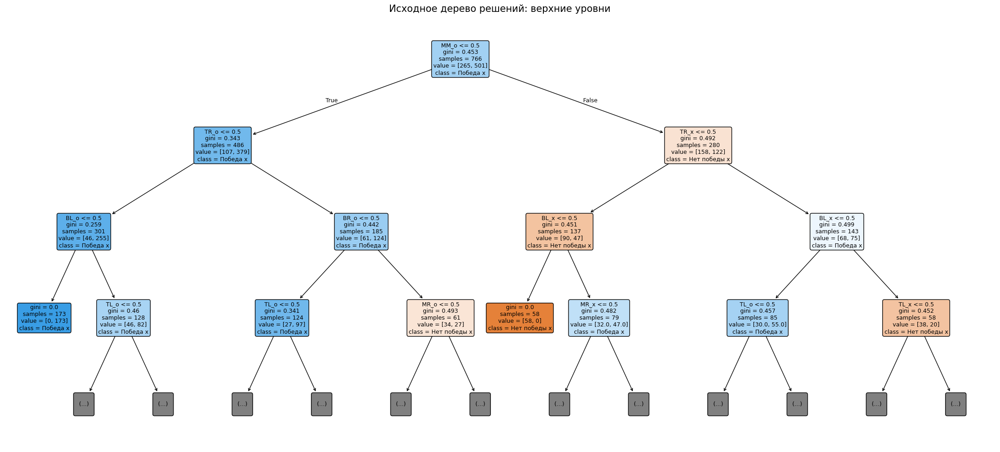

In [11]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Увеличенный фрагмент исходного дерева: корень и три уровня ниже.
# Ограничивается только отображение, сама модель dt не изменяется.
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    dt, max_depth=3,
    feature_names=X_train.columns.tolist(),
    class_names=["Нет победы x", "Победа x"],
    filled=True, rounded=True, proportion=False,
    precision=3, fontsize=9, ax=ax
)
ax.set_title("Исходное дерево решений: верхние уровни", fontsize=15)
plt.tight_layout()
plt.show()

### Как читать графическое представление дерева

Корень проверяет `MM_o <= 0.5`: слева находятся позиции без нолика в центре, справа — с ноликом. Для каждого условия левая ветвь соответствует его выполнению, правая — невыполнению. Порог 0,5 разделяет значения бинарного индикатора 0 и 1.

`samples` — число обучающих позиций в узле, `value = [n0, n1]` — количества позиций без победы `x` и с ней, `class` — класс большинства. `gini=0` означает, что все обучающие позиции узла одного класса; цвет показывает преобладающий класс, насыщенность — чистоту узла. Это характеристики обучающих данных, а не вероятность безошибочного ответа на тесте. Многоточия внизу обозначают скрытые продолжения ветвей: показан только фрагмент дерева.

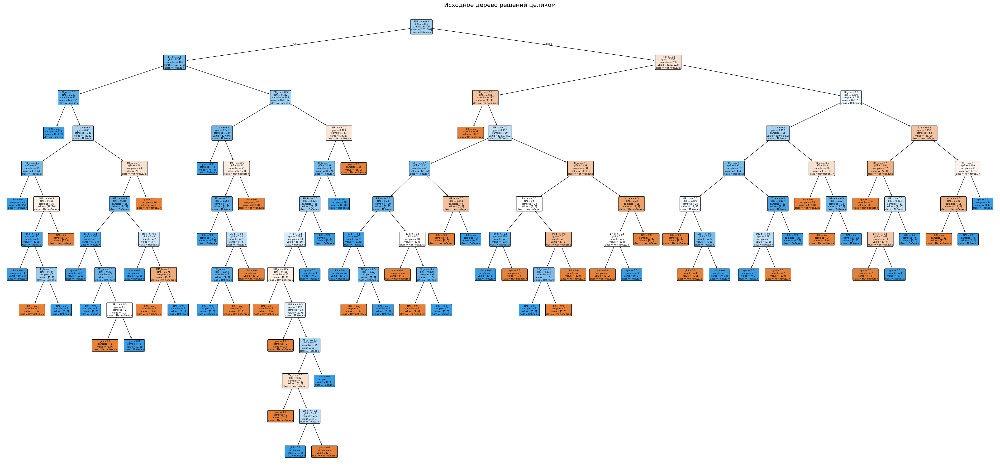

In [12]:
# Полное исходное дерево без ограничения глубины отображения.
fig, ax = plt.subplots(figsize=(38, 18))
plot_tree(
    dt,
    feature_names=X_train.columns.tolist(),
    class_names=["Нет победы x", "Победа x"],
    filled=True, rounded=True, proportion=False,
    precision=3, fontsize=6, ax=ax
)
ax.set_title("Исходное дерево решений целиком", fontsize=16)
plt.tight_layout()
plt.show()

**Интерпретация полного дерева.** Исходная модель содержит 125 узлов и 63 листа, фактическая глубина — 12. Каждый путь от корня к листу задаёт последовательность проверок индикаторов клеток и итоговый класс. Чистые листья показывают точное разделение достигших их обучающих объектов; они не отменяют 12 ошибок на тесте. Ниже отдельно подбирается ограничение глубины; показанная здесь модель — исходное дерево без такого ограничения.

In [13]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda = LinearDiscriminantAnalysis()
lda.fit(X_train, y_train)
lda_pred = lda.predict(X_test)
lda_prob = lda.predict_proba(X_test)[:, 1]

print("Метрики качества LDA:")
print("Accuracy:", accuracy_score(y_test, lda_pred))
print("Precision:", precision_score(y_test, lda_pred))
print("Recall:", recall_score(y_test, lda_pred))
print("F1-score:", f1_score(y_test, lda_pred))
print("ROC-AUC:", roc_auc_score(y_test, lda_prob))

Метрики качества LDA:
Accuracy: 0.984375
Precision: 0.9765625
Recall: 1.0
F1-score: 0.9881422924901185
ROC-AUC: 0.9984477611940298


### Интерпретация результатов LDA

Найдены все 125 побед `x`, а три из 67 остальных позиций ошибочно названы победами: пропущенных побед нет, но положительный ответ не безошибочен. Поэтому Recall = 100% сочетается с Precision = 97,7%; F1 = 0,988 соответствует высокому уровню обоих показателей. По сравнению с деревом устранены восемь пропусков и одна ложная победа, число ошибок сократилось с 12 до трёх.

ROC-AUC = 0,998 означает почти полное разделение классов по оценкам модели. В этом опыте линейной границы в пространстве индикаторов оказалось достаточно для высокого качества; это не доказывает безошибочную линейную разделимость всего набора.

In [14]:
from sklearn.svm import SVC

svm = SVC(probability=True, random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
svm_prob = svm.predict_proba(X_test)[:, 1]

print("Метрики качества SVM:")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall:", recall_score(y_test, svm_pred))
print("F1-score:", f1_score(y_test, svm_pred))
print("ROC-AUC:", roc_auc_score(y_test, svm_prob))

Метрики качества SVM:
Accuracy: 0.984375
Precision: 0.9765625
Recall: 1.0
F1-score: 0.9881422924901185
ROC-AUC: 0.9899701492537314


### Интерпретация результатов SVM

При стандартных настройках SVM получила те же количества ошибок, что и LDA: все 125 побед найдены, три непобедные позиции названы победами. Поэтому Accuracy, Precision, Recall и F1 совпали; преимущества по обычным решениям классов в этом опыте нет. Совпадение метрик не означает, что модели обязательно ошиблись на одних и тех же объектах.

ROC-AUC ниже, чем у LDA: 0,990 против 0,998. Следовательно, при совпавших количествах ответов SVM хуже упорядочила пары «победа — непобеда» по вероятностным оценкам. ROC-AUC и метрики итоговых классов оценивают разные свойства модели.

In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
knn_prob = knn.predict_proba(X_test)[:, 1]

print("Метрики качества kNN:")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1-score:", f1_score(y_test, knn_pred))
print("ROC-AUC:", roc_auc_score(y_test, knn_prob))

Метрики качества kNN:
Accuracy: 0.9270833333333334
Precision: 0.9172932330827067
Recall: 0.976
F1-score: 0.9457364341085271
ROC-AUC: 0.9794029850746268


### Интерпретация результатов kNN

Найдены 124 из 125 побед, но 11 из 67 остальных позиций ошибочно отнесены к победам. Recall = 99,2% означает почти полное обнаружение побед; Precision = 91,9% — примерно восемь ложных ответов на каждые сто предсказанных побед.

Accuracy совпала с деревом: обе модели допустили 12 ошибок. Однако kNN пропустил на семь побед меньше и выдал на семь ложных побед больше. Его F1 немного выше (0,954 против 0,951), а ROC-AUC = 0,974 указывает на лучшее ранжирование классов. По сравнению с LDA и SVM ошибок всё же больше: 12 против трёх.

In [16]:
models = [
    ("GaussianNB", y_pred, y_prob),
    ("MultinomialNB", mnb_pred, mnb_prob),
    ("ComplementNB", cnb_pred, cnb_prob),
    ("BernoulliNB", bnb_pred, bnb_prob),
    ("Decision Tree", dt_pred, dt_prob),
    ("LDA", lda_pred, lda_prob),
    ("SVM", svm_pred, svm_prob),
    ("kNN", knn_pred, knn_prob)
]

results = []

for name, pred, prob in models:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print("Сравнение классификаторов:")
print(results_df.round(3).to_string(index=False))

Сравнение классификаторов:
        Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
   GaussianNB     0.688      0.744   0.792     0.767    0.784
MultinomialNB     0.724      0.740   0.888     0.807    0.789
 ComplementNB     0.677      0.789   0.688     0.735    0.789
  BernoulliNB     0.719      0.752   0.848     0.797    0.790
Decision Tree     0.938      0.967   0.936     0.951    0.938
          LDA     0.984      0.977   1.000     0.988    0.998
          SVM     0.984      0.977   1.000     0.988    0.990
          kNN     0.927      0.917   0.976     0.946    0.979


**Интерпретация таблицы исходных моделей.** LDA и SVM допускают по три ошибки и одновременно имеют высокие Precision и Recall. Дерево и kNN допускают по 12 ошибок, но дерево реже выдаёт ложную победу, а kNN реже пропускает настоящую. Варианты Байеса ошибаются 53–62 раза, поэтому заметно уступают остальным моделям. Таблица относится к общей тестовой выборке, и её показатели можно сравнивать напрямую.

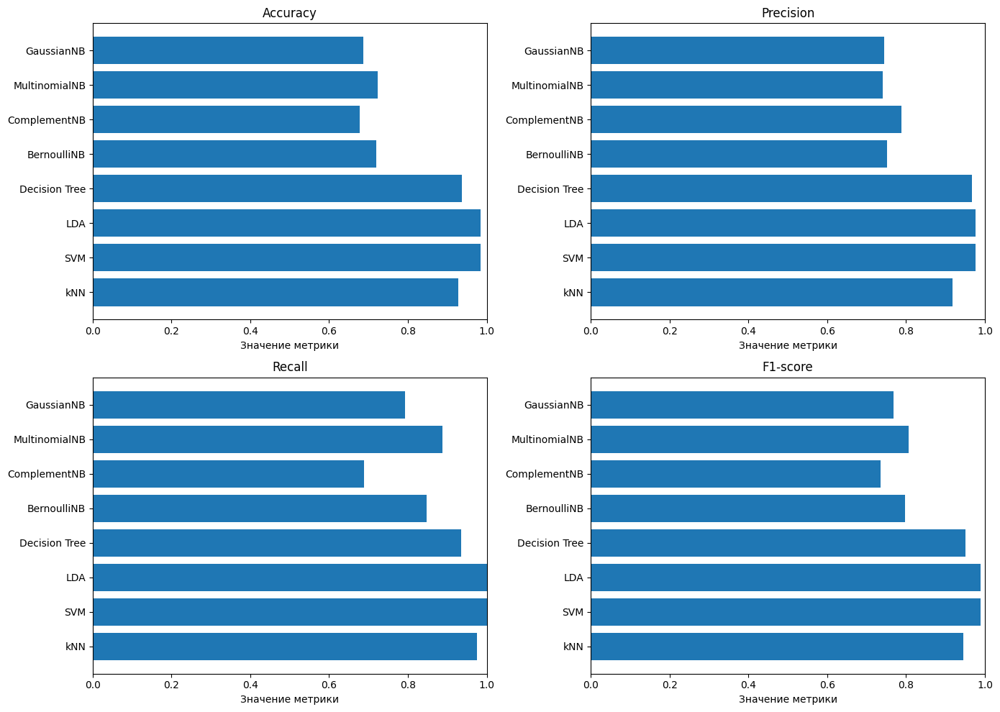

In [17]:
import matplotlib.pyplot as plt

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, metric in enumerate(metrics):
    ax = axes[i // 2, i % 2]

    # Строим столбчатую диаграмму
    ax.barh(results_df["Model"], results_df[metric])

    # Настраиваем график
    ax.set_title(metric)
    ax.set_xlabel("Значение метрики")
    ax.set_xlim(0, 1)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

### Интерпретация столбчатых диаграмм

- **Accuracy:** LDA и SVM дают меньше всего ошибок; одинаковая высота столбцов дерева и kNN отражает одинаковое общее число ошибок, но не одинаковое их распределение.
- **Precision:** дерево точнее kNN подтверждает предсказанную победу. Среди вариантов Байеса самый высокий Precision у ComplementNB, но этого недостаточно для лучшего результата в целом.
- **Recall:** LDA и SVM нашли все победы, kNN пропустил одну. ComplementNB пропускает почти треть побед, поэтому его более высокий Precision сопровождается низкой полнотой.
- **F1:** LDA и SVM лучше всего сочетают Precision и Recall. У MultinomialNB этот баланс лучше, чем у других вариантов Байеса, но хуже, чем у дерева, LDA, SVM и kNN.

Таким образом, выбирать модель только по самому высокому столбцу Recall или Precision нельзя: увеличение полноты может сопровождаться ростом числа ложных побед.

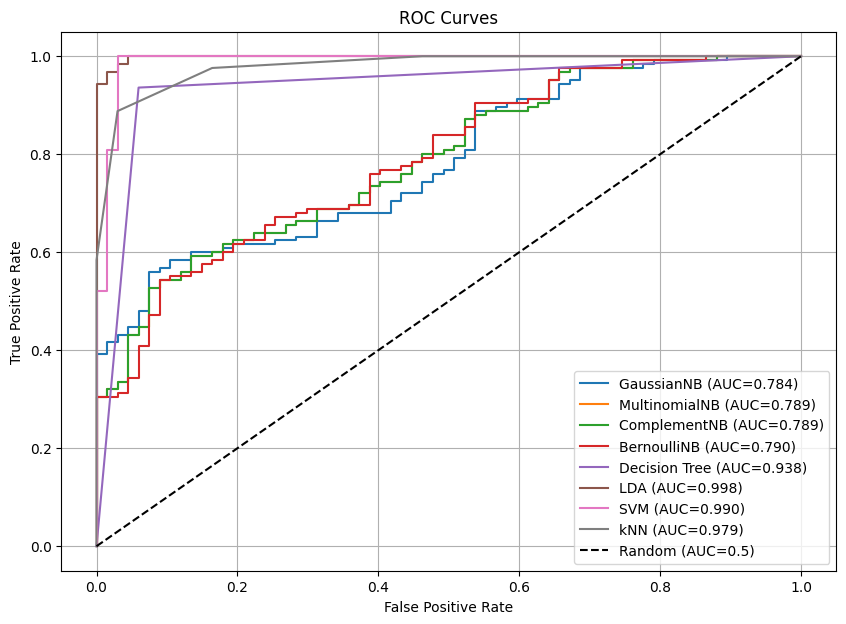

In [18]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 7))

# Строим ROC-кривую для каждой модели
for name, pred, prob in models:
    fpr, tpr, thresholds = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")

# Линия случайного угадывания
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5)")

# Настраиваем график
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.grid()

plt.show()

### Интерпретация ROC-кривых

По горизонтали показана доля непобедных позиций, ошибочно принятых за победы (FPR), по вертикали — доля найденных побед (TPR). При одинаковой доле ложных тревог более высокая кривая означает больше найденных побед. Диагональ служит ориентиром случайного ранжирования, а не Accuracy = 50%.

Наибольшая площадь у LDA, затем идут SVM, kNN и дерево: в среднем они лучше располагают победные позиции выше непобедных по оценке модели. Кривые Байеса заметно дальше от верхнего левого угла, что согласуется с их более слабым ранжированием. Одинаковые ROC-AUC у MultinomialNB и ComplementNB сочетаются с разными Precision и Recall: одинаковая оценка ранжирования не задаёт одинаковые решения классов.

alpha: 0.01 F1-score: 0.788
alpha: 0.1 F1-score: 0.788
alpha: 0.5 F1-score: 0.789
alpha: 1 F1-score: 0.789
alpha: 2 F1-score: 0.79
alpha: 5 F1-score: 0.79
alpha: 10 F1-score: 0.794
Лучший alpha: 10
Лучший F1-score: 0.794


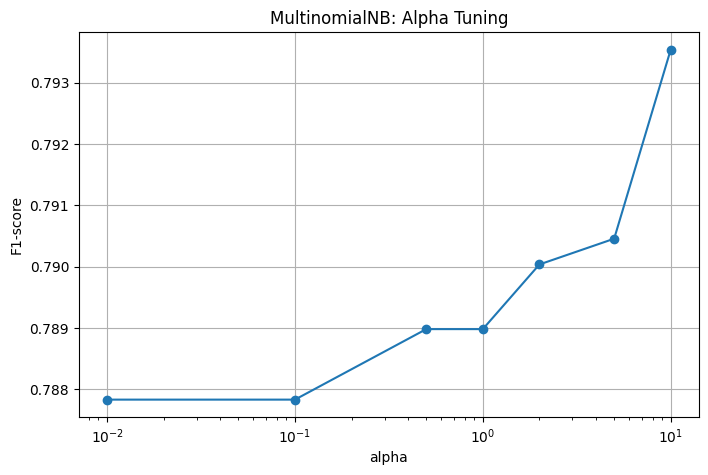

In [19]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

alpha_values = [0.01, 0.1, 0.5, 1, 2, 5, 10]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for alpha in alpha_values:
    model = MultinomialNB(alpha=alpha)

    result = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="f1"
    )

    scores.append(result.mean())

    print("alpha:", alpha, "F1-score:", round(result.mean(), 3))

# Находим лучший параметр
best_index = scores.index(max(scores))
best_alpha = alpha_values[best_index]

print("Лучший alpha:", best_alpha)
print("Лучший F1-score:", round(scores[best_index], 3))

# Строим график
plt.figure(figsize=(8, 5))
plt.plot(alpha_values, scores, marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("F1-score")
plt.title("MultinomialNB: Alpha Tuning")
plt.grid()

plt.show()

### Интерпретация влияния alpha

`alpha` сглаживает оценки вероятностей MultinomialNB. При его росте от 0,01 до 10 средний F1 на пяти проверочных блоках увеличился лишь с 0,788 до 0,794: настройка немного улучшила совместный уровень Precision и Recall, но не устранила слабое качество модели.

Выбрано `alpha=10` по наибольшему неокруглённому среднему. Максимум находится на границе проверенного диапазона, поэтому это лучший из исследованных вариантов, а не доказанный оптимум для любого alpha. График показывает кросс-валидацию обучающей выборки; влияние настройки на общий тест оценивается отдельно.

Глубина: 1 F1-score: 0.768
Глубина: 2 F1-score: 0.791
Глубина: 3 F1-score: 0.82
Глубина: 4 F1-score: 0.86
Глубина: 5 F1-score: 0.894
Глубина: 6 F1-score: 0.928
Глубина: 7 F1-score: 0.942
Глубина: 8 F1-score: 0.942
Глубина: 9 F1-score: 0.939
Глубина: 10 F1-score: 0.942
Глубина: 11 F1-score: 0.942
Глубина: 12 F1-score: 0.942
Глубина: 13 F1-score: 0.942
Глубина: 14 F1-score: 0.942
Глубина: 15 F1-score: 0.942
Глубина: None F1-score: 0.942
Лучшая глубина: 8
Лучший F1-score: 0.942


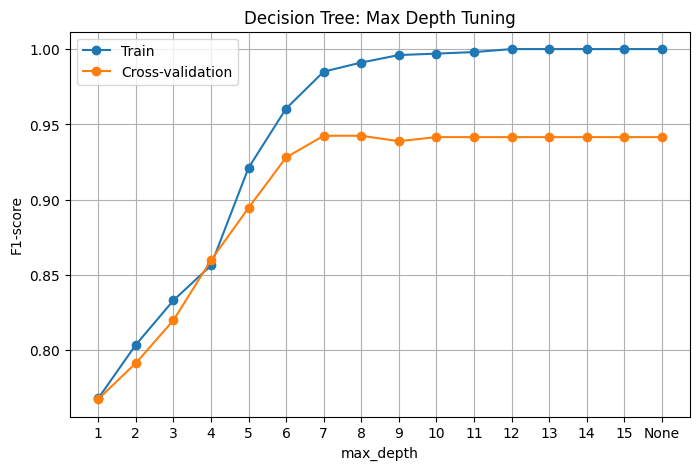

In [20]:
# Значения глубины дерева
depth_values = list(range(1, 16)) + [None]

train_scores = []
cv_scores = []

for depth in depth_values:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # Обучаем модель
    tree.fit(X_train, y_train)

    # F1-score на обучающей выборке
    train_pred = tree.predict(X_train)
    train_f1 = f1_score(y_train, train_pred)
    train_scores.append(train_f1)

    # F1-score при кросс-валидации
    result = cross_val_score(
        tree, X_train, y_train,
        cv=cv,
        scoring="f1"
    )

    cv_scores.append(result.mean())

    print("Глубина:", depth, "F1-score:", round(result.mean(), 3))

# Находим лучшую глубину
best_index = cv_scores.index(max(cv_scores))
best_depth = list(depth_values)[best_index]

print("Лучшая глубина:", best_depth)
print("Лучший F1-score:", round(cv_scores[best_index], 3))

# Строим график
plt.figure(figsize=(8, 5))

depth_labels = [str(d) if d is not None else "None" for d in depth_values]
plt.plot(depth_labels, train_scores, marker="o", label="Train")
plt.plot(depth_labels, cv_scores, marker="o", label="Cross-validation")

plt.xlabel("max_depth")
plt.ylabel("F1-score")
plt.title("Decision Tree: Max Depth Tuning")
plt.legend()
plt.grid()

plt.show()

### Интерпретация влияния глубины дерева

Мелкое дерево недостаточно точно описывает зависимость исхода от клеток: при глубине 1 F1 низок и на обучении, и при кросс-валидации. С ростом глубины до 7–8 качество на проверочных блоках повышается примерно до 0,942. Затем обучающий F1 продолжает расти и при глубине 12 достигает 1, а проверочный почти не меняется. Это признак подгонки к обучающим объектам без улучшения обобщения.

Выбрана глубина 8 по максимальному неокруглённому среднему. Результат глубины 7 отличается примерно на 0,00002 F1, поэтому график не даёт оснований считать преимущество глубины 8 существенным. Ограничение глубины сдерживает сложность дерева, но не гарантирует улучшения на отдельной тестовой выборке.

shrinkage: 0 F1-score: 0.747
shrinkage: 0.1 F1-score: 0.935
shrinkage: 0.2 F1-score: 0.867
shrinkage: 0.4 F1-score: 0.811
shrinkage: 0.6 F1-score: 0.783
shrinkage: 0.8 F1-score: 0.77
shrinkage: 1.0 F1-score: 0.763
Лучший shrinkage: 0.1
Лучший F1-score: 0.935


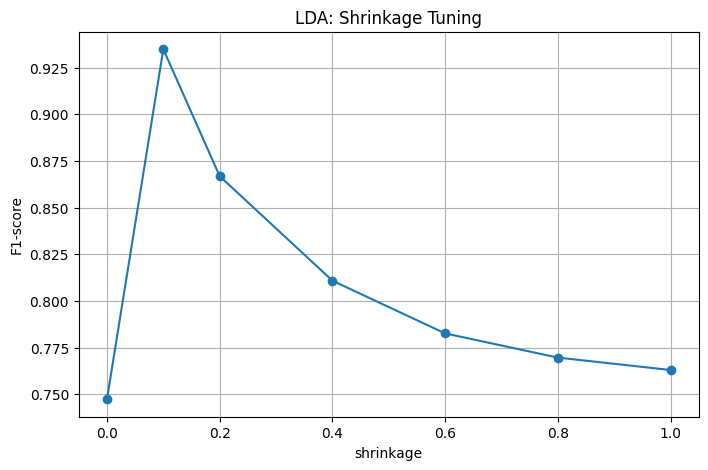

In [21]:
# Значения гиперпараметра
shrinkage_values = [0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]

scores = []

for value in shrinkage_values:
    model = LinearDiscriminantAnalysis(
        solver="lsqr",
        shrinkage=value
    )

    result = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="f1"
    )

    scores.append(result.mean())

    print("shrinkage:", value, "F1-score:", round(result.mean(), 3))

# Находим лучший параметр
best_index = scores.index(max(scores))
best_shrinkage = shrinkage_values[best_index]

print("Лучший shrinkage:", best_shrinkage)
print("Лучший F1-score:", round(scores[best_index], 3))

# Строим график
plt.figure(figsize=(8, 5))

plt.plot(shrinkage_values, scores, marker="o")

plt.xlabel("shrinkage")
plt.ylabel("F1-score")
plt.title("LDA: Shrinkage Tuning")
plt.grid()

plt.show()

### Интерпретация влияния shrinkage

При `solver="lsqr"` небольшая регуляризация (`shrinkage=0.1`) заметно улучшила F1 относительно нулевой: модель лучше сочетает точность положительных ответов и обнаружение побед. При дальнейшем усилении регуляризации качество падает, то есть более сильное сглаживание оценки ковариации здесь не помогает.

После полного one-hot-кодирования признаки линейно зависимы: индикаторы каждой клетки в сумме равны 1. Поэтому вариант без регуляризации с `lsqr` чувствителен к способу решения задачи. Этот опыт сравнивает настройки внутри `lsqr`; он не показывает, что регуляризация улучшила исходную LDA с `solver="svd"`. Эти варианты сравниваются отдельно ниже.

C: 0.01 F1-score: 0.791
C: 0.1 F1-score: 0.791
C: 0.5 F1-score: 0.911
C: 1 F1-score: 0.974
C: 5 F1-score: 0.99
C: 10 F1-score: 0.992
C: 100 F1-score: 0.992
Лучший C: 10
Лучший F1-score: 0.992


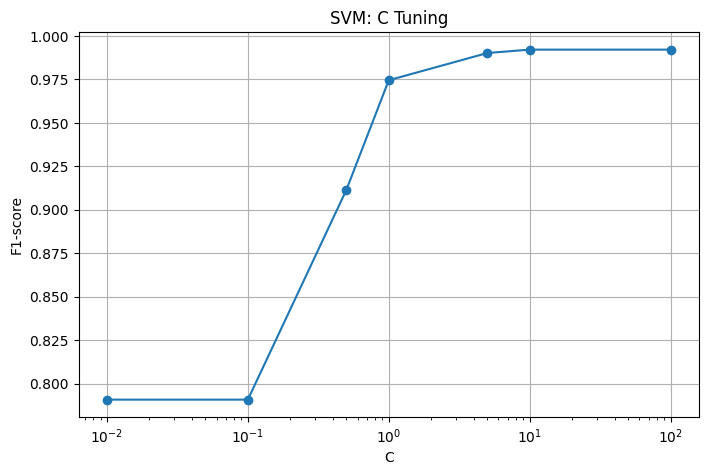

In [22]:
# Значения гиперпараметра
C_values = [0.01, 0.1, 0.5, 1, 5, 10, 100]

scores = []

for value in C_values:
    model = SVC(C=value, kernel="rbf")

    result = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="f1"
    )

    scores.append(result.mean())

    print("C:", value, "F1-score:", round(result.mean(), 3))

# Находим лучший параметр
best_index = scores.index(max(scores))
best_C = C_values[best_index]

print("Лучший C:", best_C)
print("Лучший F1-score:", round(scores[best_index], 3))

# Строим график
plt.figure(figsize=(8, 5))

plt.plot(C_values, scores, marker="o")
plt.xscale("log")

plt.xlabel("C")
plt.ylabel("F1-score")
plt.title("SVM: C Tuning")
plt.grid()

plt.show()

### Интерпретация влияния C в SVM

Малое `C` означает более сильную регуляризацию: при 0,01–0,1 качество существенно ниже, чем при более мягком ограничении модели. Рост `C` до 10 повысил проверочный F1 до 0,992, то есть улучшил совместное качество Precision и Recall. При `C=100` результат не изменился, поэтому дополнительное ослабление регуляризации в проверенном диапазоне не дало выигрыша.

Выбрано `C=10` как первое значение с максимальным средним F1. В отличие от дерева, здесь показана только проверочная кривая: по ней нельзя оценить разрыв между обучением и проверкой или утверждать отсутствие переобучения.

k: 1 F1-score: 0.843
k: 3 F1-score: 0.918
k: 5 F1-score: 0.95
k: 7 F1-score: 0.959
k: 9 F1-score: 0.974
k: 11 F1-score: 0.974
k: 13 F1-score: 0.969
k: 15 F1-score: 0.951
k: 17 F1-score: 0.93
k: 19 F1-score: 0.915
k: 21 F1-score: 0.893
k: 23 F1-score: 0.891
k: 25 F1-score: 0.882
Лучшее k: 9
Лучший F1-score: 0.974


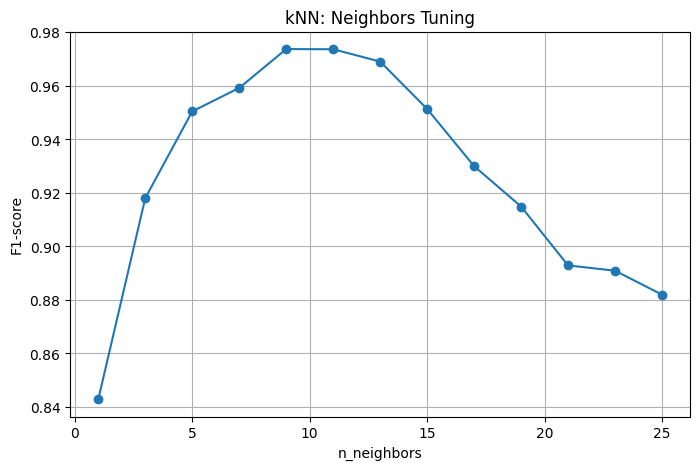

In [23]:
# Количество ближайших соседей
k_values = range(1, 26, 2)

scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)

    result = cross_val_score(
        model, X_train, y_train,
        cv=cv,
        scoring="f1"
    )

    scores.append(result.mean())

    print("k:", k, "F1-score:", round(result.mean(), 3))

# Находим лучший параметр
best_index = scores.index(max(scores))
best_k = k_values[best_index]

print("Лучшее k:", best_k)
print("Лучший F1-score:", round(scores[best_index], 3))

# Строим график
plt.figure(figsize=(8, 5))

plt.plot(k_values, scores, marker="o")

plt.xlabel("n_neighbors")
plt.ylabel("F1-score")
plt.title("kNN: Neighbors Tuning")
plt.grid()

plt.show()

### Интерпретация влияния числа соседей

При `k=1` решение зависит от одной ближайшей позиции и сильнее реагирует на локальные особенности данных. Увеличение соседства до 11–13 улучшило проверочный F1: голосование стало лучше обобщать классы. При дальнейшем росте до 25 качество падает — более широкое соседство сглаживает полезные различия между позициями.

Выбрано `k=13` по неокруглённому среднему. Разница с `k=11` меньше 0,0001 F1, поэтому результат скорее указывает на близкую по качеству область 11–13, чем на убедительное преимущество ровно 13 соседей.

### Выбор настроек классических моделей

Лучшие параметры выбираются по среднему F1 на тех же пяти блоках кросс-валидации. Для LDA дополнительно проверяется исходный `solver="svd"`; тест при выборе параметров не используется. В семействе Байеса настраивается MultinomialNB.

In [24]:
# Сравниваем исходную LDA и лучший вариант с регуляризацией
lda_default_cv = cross_val_score(
    LinearDiscriminantAnalysis(), X_train, y_train,
    cv=cv, scoring="f1"
).mean()

lda_shrinkage_cv = cross_val_score(
    LinearDiscriminantAnalysis(solver="lsqr", shrinkage=best_shrinkage),
    X_train, y_train, cv=cv, scoring="f1"
).mean()

if lda_default_cv >= lda_shrinkage_cv:
    best_lda = LinearDiscriminantAnalysis()
    lda_settings = 'solver=svd, shrinkage=None'
    best_lda_cv = lda_default_cv
else:
    best_lda = LinearDiscriminantAnalysis(
        solver="lsqr", shrinkage=best_shrinkage
    )
    lda_settings = f'solver=lsqr, shrinkage={best_shrinkage}'
    best_lda_cv = lda_shrinkage_cv

print("LDA, исходная: F1 CV =", round(lda_default_cv, 3))
print("LDA, shrinkage: F1 CV =", round(lda_shrinkage_cv, 3))
print("Выбранные настройки:")
print("MultinomialNB: alpha =", best_alpha)
print("Decision Tree: max_depth =", best_depth)
print("LDA:", lda_settings)
print("SVM: C =", best_C)
print("kNN: k =", best_k)

LDA, исходная: F1 CV = 0.987
LDA, shrinkage: F1 CV = 0.935
Выбранные настройки:
MultinomialNB: alpha = 10
Decision Tree: max_depth = 8
LDA: solver=svd, shrinkage=None
SVM: C = 10
kNN: k = 9


### Интерпретация выбора настроек

Исходная LDA с `solver="svd"` лучше варианта `lsqr, shrinkage=0.1` по среднему F1 (0,987 против 0,935), поэтому регуляризованный вариант не принят. Улучшение внутри одной серии настроек не означает преимущества перед исходной моделью.

Остальные параметры также выбраны по проверочным блокам обучающей выборки. Их результат на тесте ниже проверяется отдельно: максимальный F1 кросс-валидации не является гарантией роста качества на любых новых объектах. GaussianNB, ComplementNB и BernoulliNB остаются без настройки, поэтому их итоговые ответы должны совпасть с исходными.

### Нейронная сеть TensorFlow

Исходная архитектура: 27 входов → Dense(16, ReLU) → Dense(8, ReLU) → Dense(1, sigmoid). Использованы Adam с `learning_rate=0.001` и binary_crossentropy; порог класса — 0,5.

Из 766 обучающих объектов выделены 612 для обучения сети и 154 для валидации с сохранением долей классов. Во всех экспериментах используются одинаковые объекты и seed = 42.

In [25]:
import os
import platform
import uuid

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import tensorflow as tf
from tensorflow import keras
import sklearn

tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2,
    random_state=SEED, stratify=y_train
)
X_fit_nn = X_fit.to_numpy(dtype="float32")
X_val_nn = X_val.to_numpy(dtype="float32")
y_fit_nn = y_fit.to_numpy(dtype="float32")
y_val_nn = y_val.to_numpy(dtype="float32")

log_root = Path("logs") / ("lr2_" + uuid.uuid4().hex[:8])
print("Обучение сети:", X_fit_nn.shape)
print("Валидация:", X_val_nn.shape)

Python: 3.13.18
NumPy: 2.1.3
Pandas: 2.2.3
Scikit-Learn: 1.6.1
TensorFlow: 2.21.0
Keras: 3.13.2
Обучение сети: (612, 27)
Валидация: (154, 27)


**Интерпретация подготовки нейросети.** Из 766 обучающих позиций 154 выделены для выбора настроек; веса в сравнительных опытах обучаются только на оставшихся 612. Общий тест из 192 позиций в этот подбор не входит. Размер входа 27 совпадает с числом индикаторов после кодирования. Версии библиотек и фиксированный seed помогают воспроизвести опыт, но не заменяют проверку на других разбиениях.

In [26]:
def build_network(hidden_layers, activation):
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    network = keras.Sequential([keras.Input(shape=(X.shape[1],))])
    for neurons in hidden_layers:
        network.add(keras.layers.Dense(neurons, activation=activation))
    network.add(keras.layers.Dense(1, activation="sigmoid"))
    network.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy", metrics=["accuracy"]
    )
    return network


def make_dataset(features, targets, batch_size, training=False):
    dataset = tf.data.Dataset.from_tensor_slices((features, targets))
    if training:
        dataset = dataset.shuffle(len(features), seed=SEED)
    options = tf.data.Options()
    options.threading.private_threadpool_size = 1
    return dataset.batch(batch_size).with_options(options)


def get_metrics(targets, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(targets, predictions),
        "Precision": precision_score(targets, predictions, zero_division=0),
        "Recall": recall_score(targets, predictions, zero_division=0),
        "F1-score": f1_score(targets, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(targets, probabilities)
    }


baseline_config = {
    "hidden_layers": (16, 8), "activation": "relu",
    "epochs": 50, "batch_size": 32
}

# В каждом опыте меняется один параметр относительно исходной сети
experiments = [
    ("baseline", "baseline", {}),
    ("epochs_20", "epochs", {"epochs": 20}),
    ("epochs_100", "epochs", {"epochs": 100}),
    ("batch_16", "batch", {"batch_size": 16}),
    ("batch_64", "batch", {"batch_size": 64}),
    ("layers_1", "layers", {"hidden_layers": (16,)}),
    ("layers_3", "layers", {"hidden_layers": (16, 8, 4)}),
    ("neurons_small", "neurons", {"hidden_layers": (8, 4)}),
    ("neurons_large", "neurons", {"hidden_layers": (32, 16)}),
    ("activation_tanh", "activation", {"activation": "tanh"}),
    ("activation_sigmoid", "activation", {"activation": "sigmoid"})
]

nn_configs = {}
nn_histories = {}
nn_rows = []

for name, group, changes in experiments:
    config = baseline_config | changes
    nn_configs[name] = config
    network = build_network(config["hidden_layers"], config["activation"])
    train_ds = make_dataset(
        X_fit_nn, y_fit_nn, config["batch_size"], training=True
    )
    val_ds = make_dataset(X_val_nn, y_val_nn, config["batch_size"])
    tb = keras.callbacks.TensorBoard(
        log_dir=str(log_root / name), update_freq="epoch",
        write_graph=False, profile_batch=0
    )
    history = network.fit(
        train_ds, validation_data=val_ds, epochs=config["epochs"],
        callbacks=[tb], verbose=0, shuffle=False
    )
    nn_histories[name] = history.history
    val_prob = network(X_val_nn, training=False).numpy().ravel()
    val_pred = (val_prob >= 0.5).astype(int)
    val_metrics = get_metrics(y_val, val_pred, val_prob)
    nn_rows.append({
        "Run": name, "Group": group,
        "Layers": str(config["hidden_layers"]),
        "Activation": config["activation"],
        "Epochs": config["epochs"], "Batch": config["batch_size"],
        "Train accuracy": history.history["accuracy"][-1],
        "Val accuracy": val_metrics["Accuracy"],
        "Val F1": val_metrics["F1-score"],
        "Val ROC-AUC": val_metrics["ROC-AUC"],
        "Val loss": history.history["val_loss"][-1]
    })
    print(name, "Val F1 =", round(val_metrics["F1-score"], 3), flush=True)

nn_results = pd.DataFrame(nn_rows)
print("Результаты экспериментов:")
print(nn_results.drop(columns=["Group", "Val ROC-AUC"]).round(3).to_string(index=False))

# При равном F1 выбираем меньшую ошибку на валидации
best_nn_name = nn_results.sort_values(
    ["Val F1", "Val loss"], ascending=[False, True], kind="stable"
).iloc[0]["Run"]
best_nn_config = nn_configs[best_nn_name]
print("Лучший вариант:", best_nn_name)
print("Настройки:", best_nn_config)

baseline Val F1 = 0.971
epochs_20 Val F1 = 0.824
epochs_100 Val F1 = 0.971
batch_16 Val F1 = 0.976
batch_64 Val F1 = 0.928
layers_1 Val F1 = 0.854
layers_3 Val F1 = 0.971
neurons_small Val F1 = 0.849
neurons_large Val F1 = 0.971
activation_tanh Val F1 = 0.976
activation_sigmoid Val F1 = 0.809
Результаты экспериментов:
               Run     Layers Activation  Epochs  Batch  Train accuracy  Val accuracy  Val F1  Val loss
          baseline    (16, 8)       relu      50     32           0.987         0.961   0.971     0.202
         epochs_20    (16, 8)       relu      20     32           0.796         0.753   0.824     0.461
        epochs_100    (16, 8)       relu     100     32           0.993         0.961   0.971     0.122
          batch_16    (16, 8)       relu      50     16           0.989         0.968   0.976     0.141
          batch_64    (16, 8)       relu      50     64           0.946         0.903   0.928     0.301
          layers_1      (16,)       relu      50     32 

**Интерпретация таблицы экспериментов.** Лучшие варианты по валидационному F1 — `batch_16` и `activation_tanh`: оба правильно определили 149 из 154 позиций, на одну больше исходной сети. Для выбора между ними использована меньшая binary crossentropy: 0,141 у `batch_16` против 0,147. Это преимущество по вероятностной функции потерь, а не дополнительное уменьшение числа ошибок классов.

Более высокая обучающая Accuracy у `neurons_large` не сопровождается лучшим валидационным F1, поэтому усложнение сети не дало выигрыша на проверке. Выбранный вариант — два скрытых слоя (16, 8), ReLU, 50 эпох и батч 16. Метрики этой таблицы относятся к валидации; напрямую сопоставлять их с тестовыми метриками классических моделей нельзя.

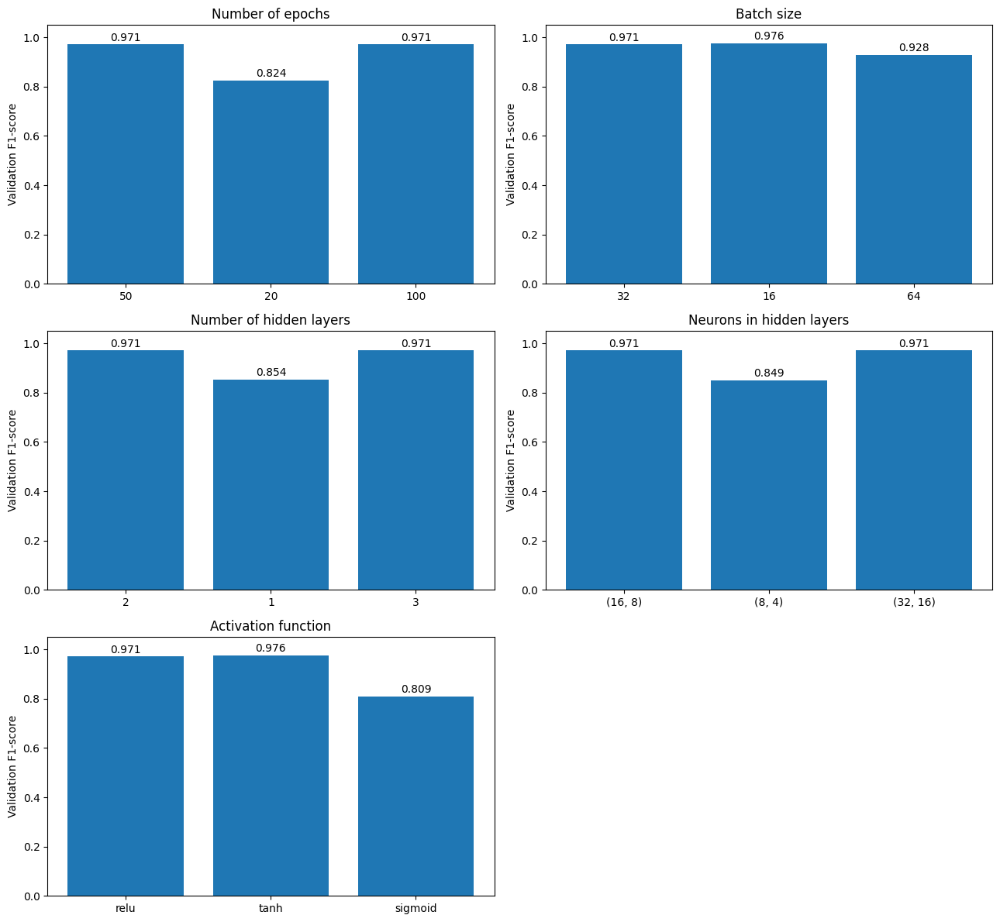

In [27]:
# Влияние каждого параметра на F1 при фиксированных остальных настройках
groups = [
    ("epochs", "Epochs", "Number of epochs"),
    ("batch", "Batch", "Batch size"),
    ("layers", "Layers", "Number of hidden layers"),
    ("neurons", "Layers", "Neurons in hidden layers"),
    ("activation", "Activation", "Activation function")
]
fig, axes = plt.subplots(3, 2, figsize=(13, 12))
for ax, (group, column, title) in zip(axes.flat, groups):
    subset = nn_results[nn_results["Group"].isin(["baseline", group])].copy()
    if group == "layers":
        labels = [str(len(nn_configs[name]["hidden_layers"])) for name in subset["Run"]]
    else:
        labels = subset[column].astype(str)
    ax.bar(labels, subset["Val F1"])
    ax.set_title(title)
    ax.set_ylabel("Validation F1-score")
    ax.set_ylim(0, 1.05)
    for i, score in enumerate(subset["Val F1"]):
        ax.text(i, score + 0.015, f"{score:.3f}", ha="center")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### Интерпретация графиков гиперпараметров нейросети

На каждом графике меняется один параметр относительно исходной сети; остальные настройки и валидационные объекты совпадают.

- **Эпохи:** при 20 эпохах низки и обучающая, и валидационная Accuracy — сеть ещё недостаточно обучилась. К 50 эпохам число валидационных ошибок сократилось с 38 до 6. Ещё 50 эпох не уменьшили это число, хотя меньшая val_loss означает улучшение вероятностных оценок по логарифмической функции потерь.
- **Батч:** при 16 объектах допущено пять валидационных ошибок, при 32 — шесть, при 64 — пятнадцать. За одно и то же число эпох маленький батч даёт больше обновлений весов; поэтому здесь сравнивается и размер батча, и разное число шагов оптимизации.
- **Скрытые слои:** второй слой заметно улучшил результат относительно одного. Третий слой не улучшил F1, поэтому в этом опыте дополнительная глубина не дала выигрыша по качеству классификации.
- **Нейроны:** сеть (8, 4) хуже исходной и на обучении, и на валидации. Удвоение исходной ширины до (32, 16) повысило обучающую Accuracy, но не валидационный F1: лучшее описание обучающих данных не превратилось в лучший результат на проверке.
- **Активация:** tanh дал на одну ошибку меньше, чем ReLU при том же батче 32. Sigmoid в скрытых слоях при выбранных 50 эпохах дал низкое качество на обеих выборках. Этот результат относится к данному режиму обучения и не доказывает, что sigmoid всегда хуже.

Малые различия получены на одном разбиении и одном seed; графики не подтверждают их статистическую устойчивость.

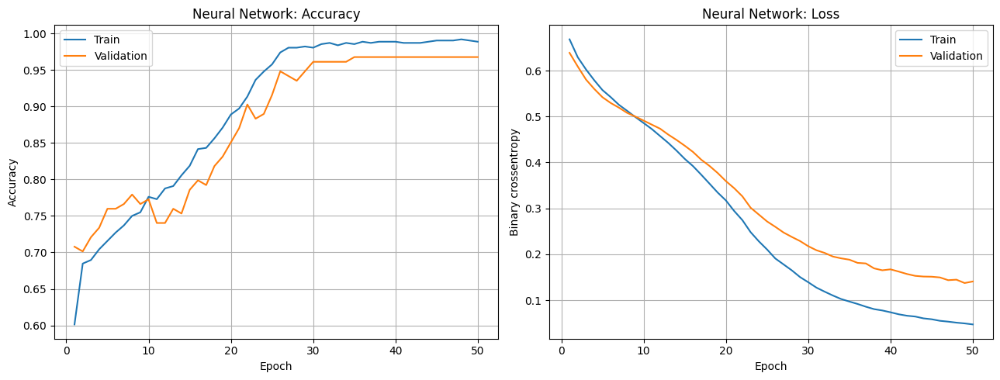

In [28]:
# Кривые лучшего варианта на фиксированном разбиении 612/154
best_history = nn_histories[best_nn_name]
epochs_axis = range(1, len(best_history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(epochs_axis, best_history["accuracy"], label="Train")
axes[0].plot(epochs_axis, best_history["val_accuracy"], label="Validation")
axes[0].set_title("Neural Network: Accuracy")
axes[0].set_ylabel("Accuracy")
axes[1].plot(epochs_axis, best_history["loss"], label="Train")
axes[1].plot(epochs_axis, best_history["val_loss"], label="Validation")
axes[1].set_title("Neural Network: Loss")
axes[1].set_ylabel("Binary crossentropy")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()

### Интерпретация кривых обучения

До примерно 30-й эпохи растёт Accuracy обеих выборок: сеть извлекает зависимости, полезные и для новых позиций. Затем валидационная Accuracy выходит на плато около 96,8% (пять ошибок из 154), хотя обучающая достигает 98,9%. Дальнейшее обучение почти не меняет количество правильных классов на валидации.

Валидационная loss при этом снизилась с 0,639 до 0,141: вероятностные предсказания продолжают улучшаться по binary crossentropy, даже когда границу 0,5 перестаёт пересекать заметное число объектов. Loss обучения ниже валидационной, а разрыв Accuracy составляет 2,1 процентного пункта — обучающие данные модель описывает лучше. Устойчивого роста валидационной loss на показанном интервале нет, поэтому явного ухудшения валидационного качества от продолжения обучения здесь не наблюдается.

### Мониторинг TensorBoard

Для каждого эксперимента записаны `accuracy`, `loss`, `val_accuracy`, `val_loss`. Наличие рядов проверяется ниже; графики лучшего варианта также сохранены выше. Последняя ячейка этого раздела открывает интерактивную панель в Google Colab.

In [29]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

tb_rows = []
for split in ["train", "validation"]:
    accumulator = EventAccumulator(
        str(log_root / best_nn_name / split), size_guidance={"tensors": 0}
    )
    accumulator.Reload()
    for tag in ["epoch_accuracy", "epoch_loss"]:
        points = accumulator.Tensors(tag)
        first = float(tf.make_ndarray(points[0].tensor_proto))
        last = float(tf.make_ndarray(points[-1].tensor_proto))
        tb_rows.append({
            "Split": split, "Metric": tag,
            "Epochs": len(points), "First": first, "Last": last
        })
print("Проверка данных TensorBoard:")
print(pd.DataFrame(tb_rows).round(3).to_string(index=False))

Проверка данных TensorBoard:
     Split         Metric  Epochs  First  Last
     train epoch_accuracy      50  0.601 0.989
     train     epoch_loss      50  0.668 0.047
validation epoch_accuracy      50  0.708 0.968
validation     epoch_loss      50  0.639 0.141


**Интерпретация данных TensorBoard.** Для каждого ряда сохранены все 50 эпох, поэтому журнал содержит полный ход выбранного обучения. Accuracy выросла на обеих выборках, а loss снизилась: улучшались и решения классов, и вероятностные оценки по функции потерь. Итоговая валидационная loss выше обучающей (0,141 против 0,047), что отражает худшее описание новых объектов. Таблица подтверждает начало и конец рядов; их промежуточное поведение видно на кривых выше и в TensorBoard.

In [30]:
%load_ext tensorboard
%tensorboard --logdir $log_root

<IPython.core.display.Javascript object>

**Интерпретация панели TensorBoard.** При выборе запуска `batch_16` отображаются те же кривые, что приведены выше: валидационная Accuracy выходит на плато, а валидационная loss продолжает снижаться. Панель служит для просмотра динамики и не является отдельной оценкой качества на общем тесте.

### Итоговое обучение и тестирование

После выбора настроек классические модели и нейросеть обучаются на всех 766 обучающих объектах. Итоговые метрики вычисляются на общих 192 тестовых объектах; для нейросети используется порог 0,5.

Настройки выбраны по кросс-валидации или валидации, а не по тестовым метрикам. Поскольку результаты этого же теста уже показаны для исходных моделей, дальнейший подбор по итоговой таблице сделал бы тест частью настройки. Ниже используется уже выбранная конфигурация.

In [31]:
final_estimators = [
    ("GaussianNB", GaussianNB()),
    ("MultinomialNB", MultinomialNB(alpha=best_alpha)),
    ("ComplementNB", ComplementNB()),
    ("BernoulliNB", BernoulliNB()),
    ("Decision Tree", DecisionTreeClassifier(max_depth=best_depth, random_state=SEED)),
    ("LDA", best_lda),
    ("SVM", SVC(C=best_C, kernel="rbf", probability=True, random_state=SEED)),
    ("kNN", KNeighborsClassifier(n_neighbors=best_k))
]

final_predictions = []
final_rows = []
for name, estimator in final_estimators:
    estimator.fit(X_train, y_train)
    pred = estimator.predict(X_test)
    prob = estimator.predict_proba(X_test)[:, 1]
    final_predictions.append((name, pred, prob))
    final_rows.append({"Model": name, **get_metrics(y_test, pred, prob)})

nn_final = build_network(
    best_nn_config["hidden_layers"], best_nn_config["activation"]
)
full_train_ds = make_dataset(
    X_train.to_numpy(dtype="float32"), y_train.to_numpy(dtype="float32"),
    best_nn_config["batch_size"], training=True
)
nn_final.fit(
    full_train_ds, epochs=best_nn_config["epochs"], verbose=0, shuffle=False,
    callbacks=[keras.callbacks.TensorBoard(
        log_dir=str(log_root / "final_full_train"),
        write_graph=False, profile_batch=0
    )]
)
nn_test_prob = nn_final(
    X_test.to_numpy(dtype="float32"), training=False
).numpy().ravel()
nn_test_pred = (nn_test_prob >= 0.5).astype(int)
final_predictions.append(("Neural Network", nn_test_pred, nn_test_prob))
final_rows.append({
    "Model": "Neural Network", **get_metrics(y_test, nn_test_pred, nn_test_prob)
})

final_results_df = pd.DataFrame(final_rows)
print("Итоговые метрики на тестовой выборке:")
print(final_results_df.round(3).to_string(index=False))

before_after = results_df[["Model", "F1-score"]].merge(
    final_results_df[["Model", "F1-score"]], on="Model",
    suffixes=(" before", " after")
)
print("F1 до и после настройки:")
print(before_after.round(3).to_string(index=False))

Итоговые метрики на тестовой выборке:
         Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
    GaussianNB     0.688      0.744   0.792     0.767    0.784
 MultinomialNB     0.729      0.739   0.904     0.813    0.791
  ComplementNB     0.677      0.789   0.688     0.735    0.789
   BernoulliNB     0.719      0.752   0.848     0.797    0.790
 Decision Tree     0.922      0.958   0.920     0.939    0.926
           LDA     0.984      0.977   1.000     0.988    0.998
           SVM     0.995      0.992   1.000     0.996    1.000
           kNN     0.964      0.954   0.992     0.973    0.997
Neural Network     0.979      0.976   0.992     0.984    0.997
F1 до и после настройки:
        Model  F1-score before  F1-score after
   GaussianNB            0.767           0.767
MultinomialNB            0.807           0.813
 ComplementNB            0.735           0.735
  BernoulliNB            0.797           0.797
Decision Tree            0.951           0.939
          LDA            

### Интерпретация итоговых метрик и настройки

SVM правильно определила 191 из 192 позиций: все 125 побед найдены, одна из 67 непобедных позиций ошибочно названа победой. Precision = 99,2% означает одну ошибку среди 126 ответов «победа», Recall = 100% — отсутствие пропусков побед. F1 = 0,996 отражает высокий совместный уровень этих показателей.

LDA допускает три ложные победы без пропусков. kNN допускает четыре ложные победы без пропусков, а нейросеть — три ложные победы и один пропуск. Поэтому у kNN и нейросети одинаковая Accuracy (188 верных ответов), но разный баланс ошибок: kNN полнее находит победы, нейросеть немного точнее подтверждает положительные ответы. F1 у них лишь совпадает после округления до трёх знаков.

После настройки kNN устранил семь ложных побед и один пропуск, SVM — две ложные победы. MultinomialNB нашёл две дополнительные победы ценой одной новой ложной, поэтому улучшение его F1 небольшое. Дерево, напротив, стало пропускать на две победы больше и выдавать на одну ложную победу больше: F1 снизился, несмотря на выбор глубины по кросс-валидации. У ненастраивавшихся вариантов Байеса и у сохранённой исходной LDA результаты не изменились.

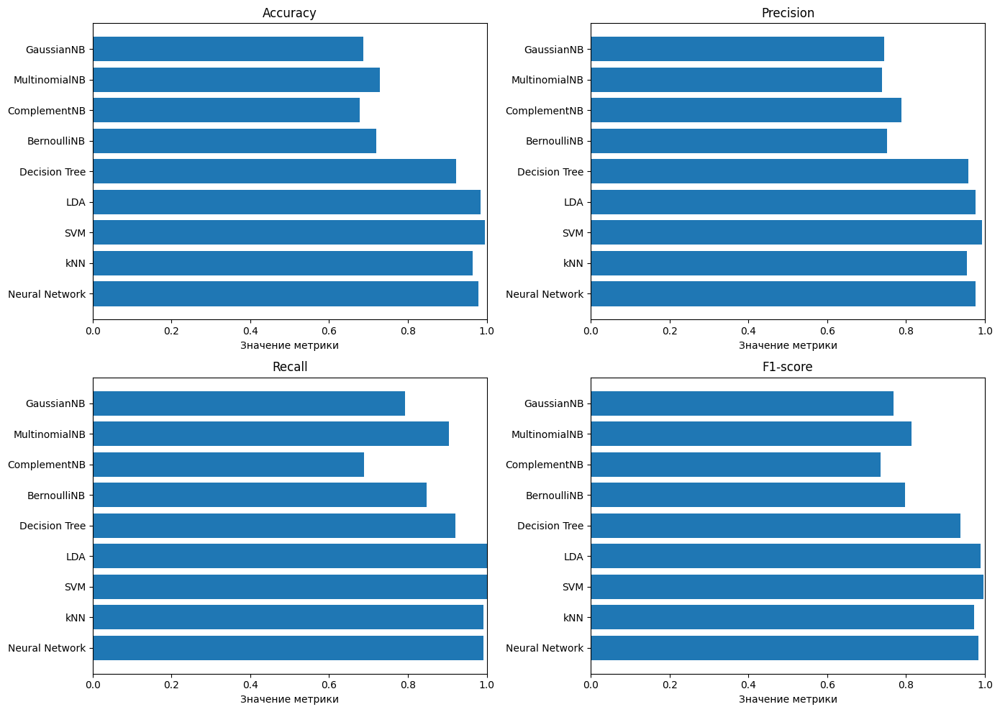

In [32]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, metric in zip(axes.flat, metrics):
    ax.barh(final_results_df["Model"], final_results_df[metric])
    ax.set_title(metric)
    ax.set_xlabel("Значение метрики")
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Интерпретация итоговых столбчатых диаграмм

SVM лидирует одновременно по Accuracy, Precision и F1, сохраняя Recall = 100%: её преимущество не получено за счёт пропуска части побед. У kNN и нейросети одинаковая высота столбца Accuracy, но kNN выше по Recall, а нейросеть — по Precision, что соответствует разному распределению четырёх ошибок.

У MultinomialNB высокий относительно других вариантов Байеса Recall сопровождается большим числом ложных побед: после настройки их 40 из 67 непобедных позиций. Поэтому один высокий столбец Recall не делает его конкурентом SVM, LDA, kNN или нейросети. По четырём панелям нужно оценивать совместный результат, а не отдельную метрику.

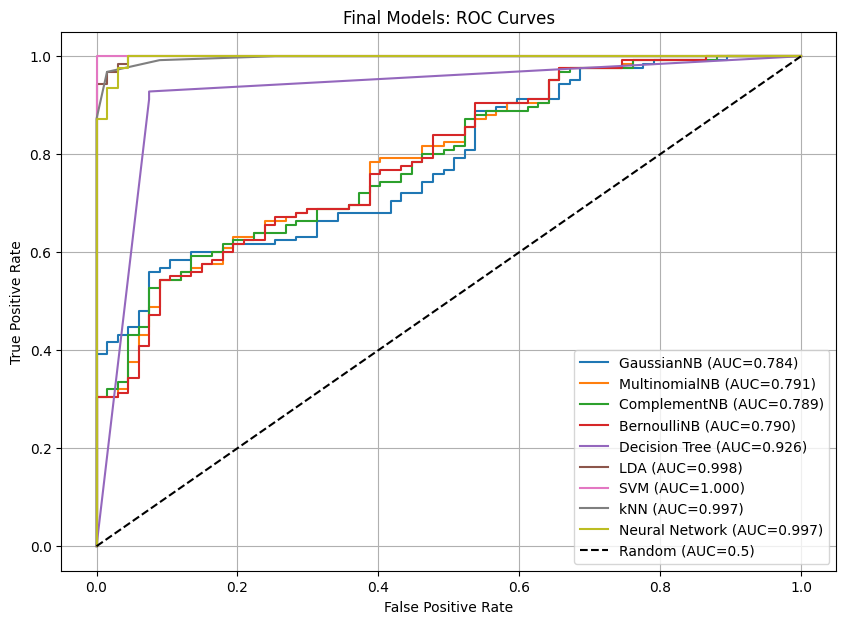

In [33]:
plt.figure(figsize=(10, 7))
for name, pred, prob in final_predictions:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random (AUC=0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Models: ROC Curves")
plt.legend()
plt.grid()
plt.show()

### Интерпретация итоговых ROC-кривых

ROC-AUC = 1 у настроенной SVM означает, что все пары «победа — непобеда» в этом тесте правильно упорядочены по её оценке. При этом стандартное правило `predict` всё равно дало одну ложную победу: идеальное ранжирование не гарантирует безошибочных решений при заданной границе классификации. Менять границу по этому тесту в рамках итоговой оценки нельзя.

LDA, kNN и нейросеть также хорошо ранжируют классы: их кривые близки к верхнему левому углу. По сравнению с исходными моделями ROC-AUC SVM и kNN вырос, а дерева снизился. Байесовские кривые остаются заметно ниже лидеров. Разницы площадей в несколько тысячных на 192 объектах недостаточно для вывода об устойчивом превосходстве на других выборках.

### Итоговый сравнительный анализ

На этом тесте SVM с `C=10` сочетает наименьшее число ошибок и наибольшие F1 и ROC-AUC. LDA уступает ей на две ошибки. kNN и нейросеть допускают по четыре ошибки, но распределяют их по-разному: kNN полнее находит победы, а нейросеть реже выдаёт ложную победу. Поэтому одинаковая Accuracy не означает одинаковую пригодность при разных требованиях к ошибкам.

Настройка существенно сократила число ошибок kNN (с 12 до 4), умеренно улучшила SVM (с 3 до 1) и MultinomialNB (с 53 до 52), а у дерева увеличила его с 12 до 15. Таким образом, подбор параметров не гарантирует улучшения на конкретном тесте. Байесовские варианты заметно уступают лидерам и по решениям классов, и по ранжированию.

### Заключение

В проведённом опыте лучший тестовый результат показала SVM с `C=10`: пропущенных побед нет, одна непобедная позиция принята за победу. Проверенная нейросеть не дала преимущества перед SVM, а увеличение её глубины, ширины или числа эпох сверх исходных значений не улучшило валидационный F1. Дерево позволяет проследить отдельные правила решения, но уступает лидерам по числу тестовых ошибок.

Результат относится к выбранному набору конечных позиций, разбиению и seed. Разница между SVM, LDA, kNN и нейросетью составляет несколько объектов; для вывода об устойчивом преимуществе нужны повторные разбиения или вложенная кросс-валидация. Качество на конечных позициях также не является оценкой умения модели выбирать ход в незавершённой игре.